<a href="https://colab.research.google.com/github/Evelandya/procesamiento-del-habla/blob/main/TP2_PH_EVELYNTRAMONTIN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo práctico 2: extracción y análisis de un documento PDF

**Objetivo general**

En este trabajo se procesa un informe en formato PDF para explorar sus metadatos y estructura textual, extraer una tabla y realizar un análisis básico de frecuencias de palabras mediante técnicas de procesamiento del lenguaje natural (NLP).

El proceso se organiza en cuatro etapas: adquisición del documento, análisis estructural del texto, extracción y limpieza de datos tabulares, y análisis de frecuencias sobre un fragmento narrativo.

Criterio de trabajo: las conclusiones se basan en los resultados que producen las celdas. La extracción automática puede presentar limitaciones cuando el PDF utiliza columnas, encabezados, pies de página o tablas complejas.

## Instalación de librerías

Se instalan las bibliotecas necesarias para descargar y leer el PDF, extraer tablas, manipular datos y realizar el análisis de texto:
- requests: descarga el archivo desde una URL.
- PyMuPDF (fitz): permite consultar metadatos y extraer texto por página y por bloques.
- pdfplumber: facilita la extracción de tablas y texto según la distribución visual de la página.
- pandas: organiza y limpia los datos tabulares.
- matplotlib: genera el gráfico de frecuencias.
- nltk: ofrece herramientas de tokenización y listas de palabras vacías (stop words).
La instalación se realiza en el entorno de Google Colab. Si las bibliotecas ya están disponibles, puede que el entorno indique que no es necesario reinstalarlas.

In [1]:
# Para evitar conflictos de dependencias con gradio, limitamos la versión de Pillow
!pip install "pillow<13.0" pymupdf pdfplumber nltk

## Importación de Librerias

En esta etapa se importan las bibliotecas y funciones que se utilizarán en las distintas secciones. Separar la instalación de la importación permite distinguir entre instalar una dependencia y utilizarla dentro del notebook.

In [35]:
import requests
import fitz
import pdfplumber
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import re
import os
import string
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


## Descarga del PDF

Se descarga el informe desde una URL pública y se guarda en la ruta indicada por ruta_pdf.

Además de comprobar que la solicitud HTTP haya sido exitosa, el código verifica que el contenido comience con la firma de un archivo PDF (%PDF-). Esta validación ayuda a detectar si la dirección devolvió una página de error u otro tipo de archivo en lugar del documento esperado.

In [3]:
url_pdf = (
      "https://learning.grupoadit.com/wp-content/uploads/2024/09/"
    "Oportunidades-y-desafios-de-la-era-de-la-inteligencia-artificial-"
    "para-la-educacion-superior-una-introduccion-para-los-actores-de-la-"
    "educacion-superior.pdf"
)

ruta_pdf = "/content/informe_ia_educacion_superior.pdf"

respuesta = requests.get(url_pdf, timeout=60)
respuesta.raise_for_status()

# Verificar que la respuesta contenga un PDF
if not respuesta.content.startswith(b"%PDF-"):
    raise ValueError("La URL no devolvió un archivo PDF válido.")

with open(ruta_pdf, "wb") as archivo:
    archivo.write(respuesta.content)

print("PDF descargado correctamente.")
print("Archivo:", ruta_pdf)
print("Tamaño:", round(os.path.getsize(ruta_pdf) / 1024, 2), "KB")


PDF descargado correctamente.
Archivo: /content/informe_ia_educacion_superior.pdf
Tamaño: 8857.47 KB


## Inspección de metadatos

Los metadatos permiten conocer información descriptiva del archivo, como título, autor, cantidad de páginas, software creador y productor del PDF. Algunos campos pueden estar vacíos o contener información técnica; eso depende de cómo se generó el documento.

También se extrae el texto de todas las páginas para obtener una primera medida de la cantidad de caracteres y observar una muestra del contenido.

In [4]:
documento = fitz.open(ruta_pdf)

print("Metadatos del documento:")
print("Título:", documento.metadata.get("title"))
print("Autor:", documento.metadata.get("author"))
print("Páginas:", len(documento))
print("Software de creación:", documento.metadata.get("creator"))
print("Productor del PDF:", documento.metadata.get("producer"))

texto_completo = "\n".join(
    pagina.get_text()
    for pagina in documento
)

print("\nCaracteres extraídos:", len(texto_completo))
print("\nPrimeros 1500 caracteres:")
print(texto_completo[:1500])

Metadatos del documento:
Título: 
Autor: 
Páginas: 94
Software de creación: Adobe InDesign 16.4 (Macintosh)
Productor del PDF: Adobe PDF Library 16.0

Caracteres extraídos: 418492

Primeros 1500 caracteres:
WORKING 
PAPERS
Oportunidades y desafíos de la era 
de la inteligencia artificial para la 
educación superior
Una introducción para los actores de la educación superior 

Publicado en 2023 por la Organización de las Naciones Unidas para la Educación, la Ciencia y la Cultura, 7, place de Fontenoy, 75352 
Paris 07 SP, Francia y el Instituto Internacional de la UNESCO para la Educación Superior en América Latina y el Caribe (IESALC), Edificio 
Asovincar, Av. Los Chorros con Calle Acueducto, Altos de Sebucán. Caracas, 1071, Venezuela.
Las ideas y opiniones expresadas en esta publicación son de los autores; no son necesariamente los de la UNESCO y no comprometen a 
la Organización.  
© UNESCO 2023
Código de documento: ED/HE/IESALC/IP/2023/27 
Esta publicación está disponible en Acceso Ab

## Interpretación de los metadatos y primera inspección

Los metadatos describen el archivo, mientras que la muestra de texto permite comprobar que el contenido es legible y que la extracción se realizó. Si algún metadato aparece como None o vacío, significa que ese campo no está informado en los metadatos del PDF; no impide continuar con el análisis.

La cantidad de caracteres es una medida inicial del volumen de texto extraído, pero no garantiza por sí sola que todo el contenido se haya recuperado en el orden correcto.

In [5]:
texto_prueba = ""

for pagina in documento:
    texto_prueba += pagina.get_text()

print(texto_prueba[:2000])
print("\nCantidad de caracteres extraídos:", len(texto_prueba))


WORKING 
PAPERS
Oportunidades y desafíos de la era 
de la inteligencia artificial para la 
educación superior
Una introducción para los actores de la educación superior 
Publicado en 2023 por la Organización de las Naciones Unidas para la Educación, la Ciencia y la Cultura, 7, place de Fontenoy, 75352 
Paris 07 SP, Francia y el Instituto Internacional de la UNESCO para la Educación Superior en América Latina y el Caribe (IESALC), Edificio 
Asovincar, Av. Los Chorros con Calle Acueducto, Altos de Sebucán. Caracas, 1071, Venezuela.
Las ideas y opiniones expresadas en esta publicación son de los autores; no son necesariamente los de la UNESCO y no comprometen a 
la Organización.  
© UNESCO 2023
Código de documento: ED/HE/IESALC/IP/2023/27 
Esta publicación está disponible en Acceso Abierto bajo la licencia Attribution-ShareAlike 3.0 IGO (CC-BY-SA 3.0 IGO) (http://
creativecommons.org/licenses/by-sa/3.0/igo/). Al utilizar el contenido de esta publicación, los usuarios aceptan estar obligad

# 2. Análisis estructural del texto

En esta sección se examina cómo está organizado el texto extraído del PDF. La extracción no siempre conserva exactamente el diseño visual original: los saltos de línea pueden responder al ancho de una columna, y los encabezados, pies de página o bloques laterales pueden mezclarse con el cuerpo del texto.

## Extracción del texto crudo

Se imprime el texto página por página sin realizar una limpieza profunda. Esta inspección inicial permite reconocer el contenido y observar posibles problemas de extracción antes de transformarlo.

In [6]:
for numero, pagina in enumerate(documento):
    print(f"\n--- PÁGINA {numero + 1} ---\n")
    print(pagina.get_text())


Se han truncado las últimas 5000 líneas del flujo de salida.
de investigación. Las herramientas de IA generativa podrían 
ayudar a formular hipótesis iniciales o diseños basados en 
los datos dados, lo que ofrece una amplia gama de puntos 
de partida para un proyecto. Las herramientas de IA pueden 
ayudar a los humanos con estímulos, fomentar el pensamiento 
lateral y promover la creatividad, los cuales son cruciales 
durante el proceso de diseño de una investigación (Figoli, 
Mattioli y Rampino, 2022). Por ejemplo, si se le da la información 
adecuada, ChatGPT puede generar marcos iniciales de 
investigación. Sin embargo, la calidad de cualquier respuesta 
de parte de las herramientas de IA generativa depende de la 
calidad de los datos de entrada proporcionados por el usuario 
humano, lo que nos recuerda la importancia fundamental de la 
intervención humana para guiar y hacer un uso responsable de 
la IA. En este sentido, las herramientas de IA pueden utilizarse 
como punto de partid

## Analisis de Separadores

Se cuentan algunos caracteres y separadores de la primera página, como saltos de línea, tabulaciones y espacios. Estos valores ayudan a describir la estructura del texto extraído, aunque no representan necesariamente párrafos reales: un salto de línea también puede aparecer al final de cada renglón impreso en el PDF.

In [8]:
texto = documento[0].get_text()

print("Saltos de línea (\\n):", texto.count("\n"))
print("Retornos de carro (\\r):", texto.count("\r"))
print("Tabulaciones (\\t):", texto.count("\t"))
print("Saltos de línea consecutivos:", texto.count("\n\n"))
print("Espacios:", texto.count(" "))


Saltos de línea (\n): 6
Retornos de carro (\r): 0
Tabulaciones (\t): 0
Saltos de línea consecutivos: 0
Espacios: 23


## Identificación de secciones y parrafos

PyMuPDF permite extraer bloques de texto con información de posición. Se muestran algunos bloques por página para observar cómo se distribuye el contenido y evaluar si la extracción respeta el orden de lectura.

Conclusión del apartado: los bloques y separadores sirven para diagnosticar la estructura del documento, pero en páginas con varias columnas es conveniente verificar visualmente el resultado antes de utilizarlo en un análisis lingüístico.

In [9]:
for numero, pagina in enumerate(documento):
    bloques = pagina.get_text("blocks")

    print(f"\nPágina {numero + 1}: {len(bloques)} bloques de texto")

    for bloque in bloques[:5]:
        print(repr(bloque[4][:200]))


Página 1: 4 bloques de texto
'WORKING \n'
'PAPERS\n'
'Oportunidades y desafíos de la era \nde la inteligencia artificial para la \neducación superior\n'
'Una introducción para los actores de la educación superior \n'

Página 2: 17 bloques de texto
'Publicado en 2023 por la Organización de las Naciones Unidas para la Educación, la Ciencia y la Cultura, 7, place de Fontenoy, 75352 \nParis 07 SP, Francia y el Instituto Internacional de la UNESCO par'
'Las ideas y opiniones expresadas en esta publicación son de los autores; no son necesariamente los de la UNESCO y no comprometen a \nla Organización.  \n'
'© UNESCO 2023\n'
'Código de documento: ED/HE/IESALC/IP/2023/27 \n'
'Esta publicación está disponible en Acceso Abierto bajo la licencia Attribution-ShareAlike 3.0 IGO (CC-BY-SA 3.0 IGO) (http://\ncreativecommons.org/licenses/by-sa/3.0/igo/). Al utilizar el contenido de'

Página 3: 52 bloques de texto
'Oportunidades y desafíos de la era de la inteligencia artificial  \npara la educación s

**Conclusión del análisis estructural:**

La inspección de saltos de línea y bloques permite comprender cómo está organizado el texto digital del PDF. Sin embargo, la estructura física del documento (columnas, cuadros y pies de página) puede diferir de la secuencia lineal que necesita un análisis de texto. Por ese motivo, para el análisis NLP se selecciona un fragmento concreto y se revisa su extracción antes de tokenizarlo.

# 3. Extracción de datos tabulares

El objetivo de esta etapa es identificar tablas del documento y convertir una de ellas en un DataFrame de Pandas. La extracción automática puede producir filas de encabezado partidas, columnas vacías o celdas con espacios; por eso se revisan los resultados antes de analizarlos.

## Búsqueda de tablas

Se prueban dos estrategias de extracción: una basada en líneas horizontales y verticales y otra que combina líneas con alineación del texto. Probar distintas estrategias es útil porque las tablas de un PDF no siempre están delimitadas de la misma manera.

Los resultados se guardan junto con la página y la estrategia utilizada, para facilitar su inspección y selección.

In [10]:
from IPython.display import display

estrategias = {
    "líneas": {
        "vertical_strategy": "lines",
        "horizontal_strategy": "lines",
    },
    "líneas + texto": {
        "vertical_strategy": "lines",
        "horizontal_strategy": "text",
        "min_words_vertical": 2,
        "min_words_horizontal": 1,
    },
}

resultados = []

with pdfplumber.open(ruta_pdf) as pdf:
    print("Total de páginas:", len(pdf.pages))

    for num_pagina, pagina in enumerate(pdf.pages, start=1):
        firmas_pagina = set()

        for nombre, configuracion in estrategias.items():
            try:
                tablas = pagina.extract_tables(
                    table_settings=configuracion
                )
            except Exception as error:
                print(
                    f"Error en página {num_pagina}, "
                    f"estrategia {nombre}: {error}"
                )
                continue

            for tabla in tablas:
                # Limpiar espacios y eliminar filas vacías
                tabla_limpia = [
                    [
                        celda.strip() if isinstance(celda, str)
                        else celda
                        for celda in fila
                    ]
                    for fila in tabla
                    if any(
                        celda is not None and str(celda).strip()
                        for celda in fila
                    )
                ]

                # Descartar resultados demasiado pequeños
                if len(tabla_limpia) < 2:
                    continue

                if max(map(len, tabla_limpia)) < 2:
                    continue

                # Identificar resultados duplicados
                firma = tuple(
                    tuple(str(celda or "") for celda in fila)
                    for fila in tabla_limpia
                )

                if firma in firmas_pagina:
                    continue

                firmas_pagina.add(firma)

                resultados.append({
                    "pagina": num_pagina,
                    "estrategia": nombre,
                    "datos": tabla_limpia,
                })

                print(
                    f"Tabla candidata en página {num_pagina} "
                    f"(estrategia: {nombre})"
                )

print("\nTotal de tablas candidatas:", len(resultados))

Total de páginas: 94
Tabla candidata en página 3 (estrategia: líneas + texto)
Tabla candidata en página 3 (estrategia: líneas + texto)
Tabla candidata en página 3 (estrategia: líneas + texto)
Tabla candidata en página 3 (estrategia: líneas + texto)
Tabla candidata en página 3 (estrategia: líneas + texto)
Tabla candidata en página 8 (estrategia: líneas + texto)
Tabla candidata en página 8 (estrategia: líneas + texto)
Tabla candidata en página 8 (estrategia: líneas + texto)
Tabla candidata en página 8 (estrategia: líneas + texto)
Tabla candidata en página 9 (estrategia: líneas + texto)
Tabla candidata en página 12 (estrategia: líneas + texto)
Tabla candidata en página 14 (estrategia: líneas + texto)
Tabla candidata en página 14 (estrategia: líneas + texto)
Tabla candidata en página 17 (estrategia: líneas + texto)
Tabla candidata en página 17 (estrategia: líneas + texto)
Tabla candidata en página 18 (estrategia: líneas + texto)
Tabla candidata en página 21 (estrategia: líneas + texto)
Tab

In [11]:

for i, resultado in enumerate(resultados):
    print(
        f"\nTabla {i}: página {resultado['pagina']} | "
        f"Estrategia: {resultado['estrategia']}"
    )

    display(pd.DataFrame(resultado["datos"]))


Tabla 0: página 3 | Estrategia: líneas + texto


,0,1
0,1 Introducción ..................................,
1,1.1 Metodología .................................,None



Tabla 1: página 3 | Estrategia: líneas + texto


,0,1
0,2 Entender la inteligencia artificial ...........,
1,2.1 ¿Qué es la inteligencia artificial? .........,
2,2.2 Técnicas y subcampos de la IA ...............,
3,2.3 Desarrollos recientes en la IA ..............,
4,2.4 Aplicaciones comunes de la IA ...............,None



Tabla 2: página 3 | Estrategia: líneas + texto


...

,0,1,2,3,4
0,,Situación,,,Seguimiento
1,,,Objetivo,Implementación,
2,Acción,actual,,,y evaluación
3,,Para ser completado por la IES,None,None,None
4,Aumentar el número de estudiantes mujeres en l...,,,,
5,Establecer vínculos con las escuelas locales p...,,,,
6,cursos de IA.,,,,
7,Ofrecer posibilidades de tutoría a las estudia...,,,,
8,de IES en STEM para reforzar la retroalimentac...,,,,
9,Proporcionar financiación o incentivos no mone...,,,,



Tabla 65: página 78 | Estrategia: líneas


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,Oportunidades y desafíos de la era de la intel...,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
1,,,78,Tabla d,e co,ntenidos,,,Ini,ci,...,,,,None,,,,,Recomen,daciones



Tabla 66: página 78 | Estrategia: líneas + texto


,0,1,2,3,4,5,6,7,8,9,...,45,46,47,48,49,50,51,52,53,54
0,,,None,None,Oportunidades y desa,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
1,,,i,None,None,None,None,None,n,None,...,None,None,None,None,None,None,None,None,None,None
2,None,None,None,None,,None,None,u,,n,...,None,None,None,None,None,None,None,None,None,None
3,,None,,,,,,educación sup,None,None,...,None,,,,,None,None,None,None,None
4,,,10,None,None,None,None,None,None,None,...,,None,None,None,None,None,None,None,None,None
5,,,,,,,Recomendaciones,None,None,None,...,None,None,None,None,None,None,None,,,None


## Selección de la tabla

En la salida anterior se muestran las tablas candidatas detectadas y su página de origen. La tabla elegida se selecciona con el índice definido en la siguiente sección. Antes de interpretar sus valores, hay que confirmar que corresponde a la tabla deseada y que las filas y columnas se hayan extraído de manera coherente.

## Conversión de una tabla en dataframe

Se selecciona una de las tablas candidatas mediante su índice dentro de la lista resultados. La primera fila se utiliza como encabezado y las filas restantes como datos.

Importante: el índice elegido depende de los resultados de extracción obtenidos en la ejecución actual. Conviene comprobar la página y el contenido que se muestran antes de continuar, ya que el orden de las tablas candidatas puede variar si cambian las estrategias o el PDF.

In [12]:

indice_tabla = 30

tabla = resultados[indice_tabla]["datos"]

# Usar la primera fila como encabezado
encabezados = [
    str(celda).strip() if celda else f"columna_{i+1}"
    for i, celda in enumerate(tabla[0])
]

df = pd.DataFrame(tabla[1:], columns=encabezados)

df = df.replace(r"^\s*$", pd.NA, regex=True)
df = df.dropna(how="all").reset_index(drop=True)

display(df)


,¿En qué disciplinas se verá afectada más positivamente la,columna_2,columna_3,¿En qué disciplinas se verá afectada más negativamente la,columna_5
0,demanda de graduados debido a la IA?,None,<NA>,demanda de graduados debido a la IA?,None
1,Informática,55%,<NA>,Idiomas,26%
2,Medicina,9%,<NA>,Negocios y administración,14%
3,Ingeniería,8%,<NA>,Leyes,14%
4,Negocios y administración,8%,<NA>,Geografía,7%
5,Otros profesionales de la salud,4%,<NA>,Psicología,5%


## Limpieza de datos

La limpieza normaliza los nombres de las columnas, elimina filas y columnas vacías, quita espacios sobrantes y convierte los porcentajes a valores numéricos.

En la tabla seleccionada, algunos encabezados están divididos entre más de una fila y aparece una columna intermedia vacía. Por eso se realiza una limpieza específica después de la limpieza general. La fila de continuación del encabezado se identifica por su contenido, en lugar de eliminar una fila por posición, para evitar borrar accidentalmente el primer registro válido.

Conclusión del apartado: una tabla extraída automáticamente debe validarse después de cada transformación. La cantidad de filas, los nombres de las columnas y los tipos de datos permiten comprobar que la limpieza no haya eliminado información relevante.

In [13]:
# Normalización de los nombres de las columnas
df.columns = [
    str(columna).strip().lower().replace(" ", "_")
    for columna in df.columns
]

# Eliminación de filas completamente vacías
df = df.dropna(how="all")

# Eliminación de espacios al principio y al final de los textos
for columna in df.columns:
    df[columna] = df[columna].apply(
        lambda valor: valor.strip()
        if isinstance(valor, str)
        else valor
    )

# Reemplazo de cadenas vacías por valores nulos
df = df.replace(r"^\s*$", pd.NA, regex=True)

# Eliminación nuevamente filas completamente vacías
df = df.dropna(how="all")

display(df)
print("Dimensiones de la tabla:", df.shape)

,¿en_qué_disciplinas_se_verá_afectada_más_positivamente_la,columna_2,columna_3,¿en_qué_disciplinas_se_verá_afectada_más_negativamente_la,columna_5
0,demanda de graduados debido a la IA?,None,<NA>,demanda de graduados debido a la IA?,None
1,Informática,55%,<NA>,Idiomas,26%
2,Medicina,9%,<NA>,Negocios y administración,14%
3,Ingeniería,8%,<NA>,Leyes,14%
4,Negocios y administración,8%,<NA>,Geografía,7%
5,Otros profesionales de la salud,4%,<NA>,Psicología,5%


Dimensiones de la tabla: (6, 5)


In [14]:

# Eliminación de columnas completamente vacías
df = df.dropna(axis=1, how="all").copy()

# Eliminación de la columna intermedia vacía, si todavía existe
# (la columna_3 contiene únicamente valores nulos)
if "columna_3" in df.columns and df["columna_3"].isna().all():
    df = df.drop(columns=["columna_3"])

# Asignación de nombres descriptivos a las cuatro columnas restantes
df.columns = [
    "disciplina_positiva",
    "porcentaje_positivo",
    "disciplina_negativa",
    "porcentaje_negativo"
]

# Eliminación exclusiva de la fila que contiene la continuación
# de los encabezados, identificándola por su contenido
es_encabezado = (
    df["disciplina_positiva"]
    .astype("string")
    .str.contains("demanda de graduados debido a la IA", case=False, na=False)
)

df = df.loc[~es_encabezado].copy()

# Reinicio de los índices
df = df.reset_index(drop=True)

# Conversión de los porcentajes a valores numéricos
# Por ejemplo, "55%" se convierte en 55
for columna in ["porcentaje_positivo", "porcentaje_negativo"]:
    df[columna] = (
        df[columna]
        .astype("string")
        .str.replace("%", "", regex=False)
        .str.strip()
    )
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

# Visualización de la tabla limpia
display(df)

print("Dimensiones finales de la tabla:", df.shape)
print("\nInformación de la tabla:")
df.info()

,disciplina_positiva,porcentaje_positivo,disciplina_negativa,porcentaje_negativo
0,Informática,55,Idiomas,26
1,Medicina,9,Negocios y administración,14
2,Ingeniería,8,Leyes,14
3,Negocios y administración,8,Geografía,7
4,Otros profesionales de la salud,4,Psicología,5


Dimensiones finales de la tabla: (5, 4)

Información de la tabla:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   disciplina_positiva  5 non-null      object
 1   porcentaje_positivo  5 non-null      Int64 
 2   disciplina_negativa  5 non-null      object
 3   porcentaje_negativo  5 non-null      Int64 
dtypes: Int64(2), object(2)
memory usage: 302.0+ bytes


**Resultado y conclusión de la tabla limpia:**

La tabla final presenta cuatro columnas: disciplina con impacto positivo, porcentaje positivo, disciplina con impacto negativo y porcentaje negativo. Los porcentajes se convierten a números para que puedan analizarse o graficarse posteriormente.

La limpieza conserva los registros de disciplinas y elimina únicamente la fila que completa el encabezado y las columnas o filas vacías identificadas. La visualización y df.info() permiten verificar las dimensiones y los tipos de datos resultantes.

# 4. Análisis de frecuencias con NLP

En esta etapa se analiza la frecuencia de palabras en un fragmento narrativo del informe. El propósito es identificar términos representativos del contenido y reconocer las decisiones de preparación del texto que influyen en los resultados.

El análisis se realiza sobre el texto extraído del PDF; por lo tanto, la calidad del orden de lectura y la eliminación de encabezados y pies de página son importantes para obtener frecuencias interpretables.

## Página elegida, extracción del texto y conversión a minúsculas

Se selecciona la página del PDF que contiene la sección 6.3, “Aprendizaje a lo largo de la vida”. Primero se visualiza la página para reconocer su distribución y luego se extraen por separado las mitades izquierda y derecha.

Esta división es una aproximación para documentos de dos columnas. Es necesario revisar el texto obtenido porque la división por la mitad puede cortar palabras o bloques si la separación real no coincide exactamente con el centro de la página.

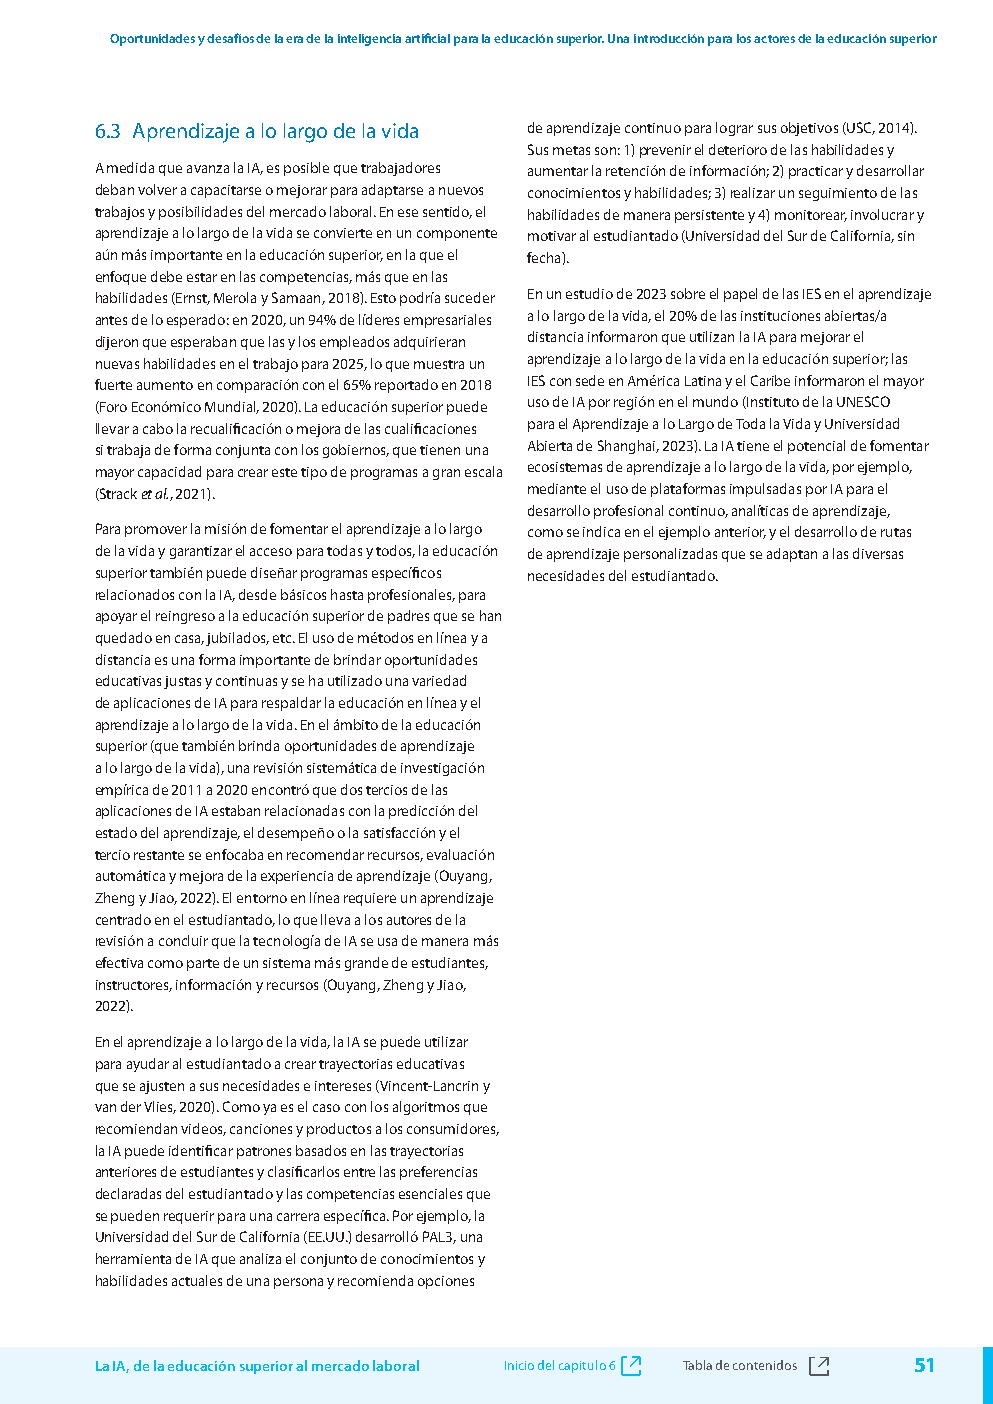

In [15]:
with pdfplumber.open(ruta_pdf) as pdf:
    pagina = pdf.pages[50]

    imagen = pagina.to_image(resolution=120)
    display(imagen.annotated)

In [21]:
with pdfplumber.open(ruta_pdf) as pdf:
    pagina = pdf.pages[50]

    ancho = pagina.width
    alto = pagina.height

    # Dividir la página en dos columnas
    columna_izquierda = pagina.crop(
        (0, 0, ancho / 2, alto)
    )

    columna_derecha = pagina.crop(
        (ancho / 2, 0, ancho, alto)
    )

    texto_izquierda = columna_izquierda.extract_text() or ""
    texto_derecha = columna_derecha.extract_text() or ""

    texto_ordenado = texto_izquierda + "\n\n" + texto_derecha

print(texto_ordenado)

Oportunidades y desafíos de la era de la inteligencia artificial para la e
6.3 Aprendizaje a lo largo de la vida
A medida que avanza la IA, es posible que trabajadores
deban volver a capacitarse o mejorar para adaptarse a nuevos
trabajos y posibilidades del mercado laboral. En ese sentido, el
aprendizaje a lo largo de la vida se convierte en un componente
aún más importante en la educación superior, en la que el
enfoque debe estar en las competencias, más que en las
habilidades (Ernst, Merola y Samaan, 2018). Esto podría suceder
antes de lo esperado: en 2020, un 94% de líderes empresariales
dijeron que esperaban que las y los empleados adquirieran
nuevas habilidades en el trabajo para 2025, lo que muestra un
fuerte aumento en comparación con el 65% reportado en 2018
(Foro Económico Mundial, 2020). La educación superior puede
llevar a cabo la recualificación o mejora de las cualificaciones
si trabaja de forma conjunta con los gobiernos, que tienen una
mayor capacidad para crear este tip

La extracción inicial puede incluir el encabezado general del informe, elementos del pie de página y texto de otras zonas de la página. Para reducir ese ruido, se recorta el texto a partir del título de la sección 6.3 y se eliminan los elementos ajenos que se identificaron durante la inspección.

Este paso es importante porque los encabezados y pies de página podrían aumentar artificialmente la frecuencia de palabras que no pertenecen al contenido narrativo analizado.

In [38]:
# Texto extraído de las dos columnas
texto = texto_ordenado

# Buscar el inicio de la sección 6.3
marcador_inicio = "6.3 Aprendizaje a lo largo de la vida"

inicio = texto.lower().find(marcador_inicio.lower())

if inicio == -1:
    raise ValueError(
        "No se encontró el título de la sección 6.3."
    )

# Conservar el texto desde el título en adelante
texto_seccion = texto[inicio:]

# Buscar posibles marcadores de contenido ajeno a la sección
marcadores_finales = [
    "6.4 ",
    "7. ",
    "Referencias bibliográficas",
    "Bibliografía"
]

# Identificar el primer marcador final que aparezca
posiciones = [
    texto_seccion.lower().find(marcador.lower())
    for marcador in marcadores_finales
]

posiciones_validas = [
    posicion for posicion in posiciones
    if posicion != -1
]

if posiciones_validas:
    texto_seccion = texto_seccion[:min(posiciones_validas)]

print(texto_seccion)


6.3 Aprendizaje a lo largo de la vida
A medida que avanza la IA, es posible que trabajadores
deban volver a capacitarse o mejorar para adaptarse a nuevos
trabajos y posibilidades del mercado laboral. En ese sentido, el
aprendizaje a lo largo de la vida se convierte en un componente
aún más importante en la educación superior, en la que el
enfoque debe estar en las competencias, más que en las
habilidades (Ernst, Merola y Samaan, 2018). Esto podría suceder
antes de lo esperado: en 2020, un 94% de líderes empresariales
dijeron que esperaban que las y los empleados adquirieran
nuevas habilidades en el trabajo para 2025, lo que muestra un
fuerte aumento en comparación con el 65% reportado en 2018
(Foro Económico Mundial, 2020). La educación superior puede
llevar a cabo la recualificación o mejora de las cualificaciones
si trabaja de forma conjunta con los gobiernos, que tienen una
mayor capacidad para crear este tipo de programas a gran escala
(Strack et al., 2021).
Para promover la misión

In [39]:
# Eliminar encabezados y pies de página conocidos
elementos_a_eliminar = [
    "Oportunidades y desafíos de la era de la inteligencia artificial para la educación superior. Una introducción para los actores de la educación superior",
    "La IA, de la educación superior al mercado laboral",
    "Inicio del capitulo 6",
    "Tabla de contenidos"
]

for elemento in elementos_a_eliminar:
    texto_seccion = re.sub(
        re.escape(elemento),
        "",
        texto_seccion,
        flags=re.IGNORECASE
    )

# Quitar el número de página aislado al final del texto
texto_seccion = re.sub(r"\s+\d+\s*$", "", texto_seccion)

# Normalizar espacios y saltos de línea
texto_seccion = re.sub(r"-\s*\n\s*", "", texto_seccion)
texto_seccion = re.sub(r"\s+", " ", texto_seccion).strip()

print("SECCIÓN 6.3 LIMPIA:\n")
print(texto_seccion)


SECCIÓN 6.3 LIMPIA:

6.3 Aprendizaje a lo largo de la vida A medida que avanza la IA, es posible que trabajadores deban volver a capacitarse o mejorar para adaptarse a nuevos trabajos y posibilidades del mercado laboral. En ese sentido, el aprendizaje a lo largo de la vida se convierte en un componente aún más importante en la educación superior, en la que el enfoque debe estar en las competencias, más que en las habilidades (Ernst, Merola y Samaan, 2018). Esto podría suceder antes de lo esperado: en 2020, un 94% de líderes empresariales dijeron que esperaban que las y los empleados adquirieran nuevas habilidades en el trabajo para 2025, lo que muestra un fuerte aumento en comparación con el 65% reportado en 2018 (Foro Económico Mundial, 2020). La educación superior puede llevar a cabo la recualificación o mejora de las cualificaciones si trabaja de forma conjunta con los gobiernos, que tienen una mayor capacidad para crear este tipo de programas a gran escala (Strack et al., 2021). Pa

In [40]:
# Convertir todo el texto a minúsculas
texto_minusculas = texto_seccion.lower()

print(texto_minusculas[:1000])

6.3 aprendizaje a lo largo de la vida a medida que avanza la ia, es posible que trabajadores deban volver a capacitarse o mejorar para adaptarse a nuevos trabajos y posibilidades del mercado laboral. en ese sentido, el aprendizaje a lo largo de la vida se convierte en un componente aún más importante en la educación superior, en la que el enfoque debe estar en las competencias, más que en las habilidades (ernst, merola y samaan, 2018). esto podría suceder antes de lo esperado: en 2020, un 94% de líderes empresariales dijeron que esperaban que las y los empleados adquirieran nuevas habilidades en el trabajo para 2025, lo que muestra un fuerte aumento en comparación con el 65% reportado en 2018 (foro económico mundial, 2020). la educación superior puede llevar a cabo la recualificación o mejora de las cualificaciones si trabaja de forma conjunta con los gobiernos, que tienen una mayor capacidad para crear este tipo de programas a gran escala (strack et al., 2021). para promover la misión

In [41]:
print("Cantidad de caracteres:", len(texto_seccion))
print("Inicio del texto:", texto_seccion[:300])
print("Final del texto:", texto_seccion[-300:])

Cantidad de caracteres: 4403
Inicio del texto: 6.3 Aprendizaje a lo largo de la vida A medida que avanza la IA, es posible que trabajadores deban volver a capacitarse o mejorar para adaptarse a nuevos trabajos y posibilidades del mercado laboral. En ese sentido, el aprendizaje a lo largo de la vida se convierte en un componente aún más important
Final del texto: la vida, por ejemplo, mediante el uso de plataformas impulsadas por IA para el desarrollo profesional continuo, analíticas de aprendizaje, como se indica en el ejemplo anterior, y el desarrollo de rutas n de aprendizaje personalizadas que se adaptan a las diversas necesidades del estudiantado. n s ,


**Justificación de la conversión a minúsculas:**

Se convierte el texto a minúsculas antes de contar las palabras para evitar que una misma palabra se contabilice en categorías separadas por diferencias de capitalización. Por ejemplo, IA e ia deben contarse como el mismo término.

La inspección del inicio y del final del texto sirve para verificar que el fragmento seleccionado comienza en el título esperado y que no conserva elementos evidentes del pie de página. En este notebook se analiza el fragmento extraído de la página seleccionada, no necesariamente toda la sección si continúa en páginas posteriores.

## Tokenización y limpieza

La tokenización divide el texto en unidades individuales llamadas tokens. Después se eliminan las palabras vacías en español (stop words), los signos de puntuación y los tokens que no están formados exclusivamente por letras.

La lista de stop words es una lista general del idioma, por lo que no elimina necesariamente todas las palabras poco relevantes para un documento específico. Por eso, después de calcular las frecuencias, se revisará si algún término que quedó en la lista podría excluirse mediante una lista personalizada.

In [42]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

# Obtener las stop words en español
stop_words = set(stopwords.words("spanish"))

# Tokenizar el texto
tokens = word_tokenize(texto_minusculas, language="spanish")

# Eliminar stop words, signos de puntuación y tokens no alfabéticos
tokens_limpios = [
    token
    for token in tokens
    if token not in stop_words
    and token not in string.punctuation
    and token.isalpha()
]

print("Cantidad de tokens antes de limpiar:", len(tokens))
print("Cantidad de tokens después de limpiar:", len(tokens_limpios))
print("\nPrimeros 50 tokens limpios:")
print(tokens_limpios[:50])


Cantidad de tokens antes de limpiar: 816
Cantidad de tokens después de limpiar: 345

Primeros 50 tokens limpios:
['aprendizaje', 'largo', 'vida', 'medida', 'avanza', 'ia', 'posible', 'trabajadores', 'deban', 'volver', 'capacitarse', 'mejorar', 'adaptarse', 'nuevos', 'trabajos', 'posibilidades', 'mercado', 'laboral', 'aprendizaje', 'largo', 'vida', 'convierte', 'componente', 'aún', 'importante', 'educación', 'superior', 'enfoque', 'debe', 'competencias', 'habilidades', 'ernst', 'merola', 'samaan', 'podría', 'suceder', 'esperado', 'líderes', 'empresariales', 'dijeron', 'esperaban', 'empleados', 'adquirieran', 'nuevas', 'habilidades', 'trabajo', 'muestra', 'fuerte', 'aumento', 'comparación']


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


**Conclusión de la tokenización y limpieza:**

Después de la tokenización se comparan las cantidades de tokens antes y después de la limpieza. La diferencia se debe a la eliminación de palabras vacías, puntuación y elementos que no son palabras alfabéticas.

Este procedimiento reduce parte del ruido lingüístico, pero depende de la lista de stop words elegida. Algunos verbos o sustantivos generales pueden seguir apareciendo entre los más frecuentes y deberán evaluarse según el contexto de la sección.

## Calculo de 15 palabras más frecuentes

Se utiliza Counter para contar cuántas veces aparece cada token limpio y se conservan las 15 palabras con mayor frecuencia. El resultado se transforma en un DataFrame para facilitar su lectura y posterior visualización.

La frecuencia indica cuántas veces aparece una palabra en el fragmento procesado; no mide por sí sola la importancia conceptual de ese término.

In [43]:
from collections import Counter
import pandas as pd

frecuencias = Counter(tokens_limpios)

df_frecuencias = pd.DataFrame(
    frecuencias.most_common(15),
    columns=["palabra", "frecuencia"]
)

display(df_frecuencias)

,palabra,frecuencia
0,aprendizaje,16
1,ia,12
2,largo,10
3,vida,10
4,educación,9
5,superior,8
6,habilidades,6
7,estudiantado,5
8,puede,4
9,uso,3


La tabla muestra los términos con mayor cantidad de apariciones en el fragmento analizado. Es esperable que palabras relacionadas con el tema de la sección, como “aprendizaje”, “vida”, “educación” e “IA”, tengan frecuencias altas.

No obstante, la frecuencia debe interpretarse en contexto: una palabra frecuente puede ser temática, pero también puede ser una palabra general que la lista estándar de stop words no haya eliminado.

## Gráfico de Barras

El gráfico horizontal facilita la comparación de las frecuencias de las 15 palabras más comunes. Se ordenan los datos para que la palabra de mayor frecuencia aparezca en la parte superior.

La visualización ayuda a identificar términos recurrentes, pero su interpretación debe tener en cuenta el tema de la sección y las limitaciones de la extracción y de la lista de stop words.

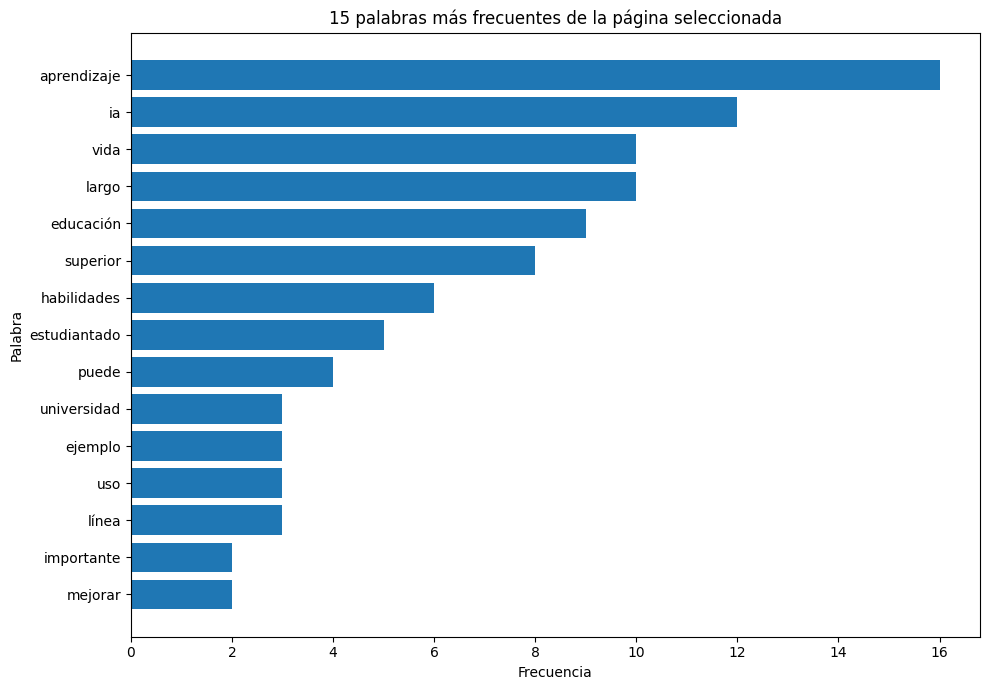

In [45]:
# Ordeno para mostrar la palabra más frecuente arriba
datos_grafico = df_frecuencias.sort_values(
    by="frecuencia",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    datos_grafico["palabra"],
    datos_grafico["frecuencia"]
)

plt.title("15 palabras más frecuentes de la página seleccionada")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()
plt.show()

Al observar el gráfico de las 15 palabras más frecuentes, identifiqué algunos tokens que podrían considerarse stop words, como "puede", "uso" y "línea". Si bien estas palabras aportan significado, en este análisis pueden tener una relevancia limitada para identificar los temas principales del texto.

Por ejemplo, "puede" es un verbo que suele utilizarse para expresar posibilidad, pero no describe por sí mismo el tema central del documento. "Uso" es una palabra general cuyo significado depende del contexto, mientras que "línea" aparece posiblemente vinculada a expresiones como "en línea", relacionadas con la educación a distancia.

Esto demuestra que eliminar las "stop words" mediante una lista predeterminada no siempre es suficiente. Es importante revisar los resultados y considerar el contexto del documento para decidir qué palabras conviene excluir. En este caso, términos como "aprendizaje", "IA", "educación" y "habilidades" son más representativos del contenido de la sección, por lo que deberían conservarse para el análisis.

# Conclusión General

El trabajo permitió recorrer un flujo básico de procesamiento de documentos: descarga y verificación del PDF, consulta de metadatos, inspección de la estructura textual, extracción y limpieza de una tabla, y análisis de frecuencias con herramientas de NLP.

Una de las principales dificultades fue que la extracción de un PDF con dos columnas puede alterar el orden de lectura e incorporar encabezados o pies de página. La inspección visual y la limpieza dirigida ayudan a reducir estos problemas, aunque es necesario comprobar el texto final y recordar que el fragmento procesado corresponde a la página seleccionada.

El gráfico muestra términos vinculados con el tema central de la sección 6.3. También evidencia que la lista general de stop words no siempre elimina todas las palabras que podrían considerarse poco informativas para un análisis particular. Por eso, los resultados automáticos deben complementarse con una revisión contextual y, si corresponde, con una lista personalizada de palabras vacías.